# F3 · Medición de eficiencia

**Proyecto:** Concentración del gasto público en salud · Región de Valparaíso · ChileCompra  
**Fase 3 · Sumativa 2** · MCDI500 Programación para la Ciencia de Datos · Grupo 5

Este notebook compara dos pares de implementaciones de operaciones reales del pipeline,
midiendo tiempo con `timeit` y memoria con `tracemalloc`. El protocolo es el de la
Figura 4 de la guía:

1. Elegir una operación real del pipeline.
2. Escribir dos versiones (por ejemplo: bucle fila por fila vs. vectorizada).
3. Comprobar que ambas producen el mismo resultado.
4. Medir repitiendo 7 veces y conservando el mínimo.
5. Interpretar: ¿cuánto más rápida es una versión, a qué costo de memoria?

---
## Comparación 1 · `apply` fila por fila vs. vectorizado con pandas

**Operación:** conversión de montos escritos con coma decimal (`'408039,1'`) a `float`.  
Esta es la función `parse_amount` de `src/pipeline/ordenes.py`, que el pipeline de F2
aplica a todas las columnas de monto antes de hacer cualquier cálculo.

- **Versión A (apply):** recorre cada celda con `Series.apply(lambda …)`.
- **Versión B (vectorizada):** reemplaza la coma con `str.replace` y convierte
  con `pd.to_numeric`, todo sin bucle explícito.

In [1]:
import timeit
import tracemalloc

import numpy as np
import pandas as pd

from pipeline import ordenes

# Semilla para reproducibilidad
rng = np.random.default_rng(42)

# Dataset sintético del mismo orden de magnitud que los datos reales
# (25 880 líneas en el dataset de órdenes de compra)
N = 25_880
enteros = rng.integers(10_000, 50_000_000, size=N)
decimales = rng.integers(0, 100, size=N)
montos_texto = pd.Series([f"{e},{d}" for e, d in zip(enteros, decimales)])

print(f"Tamaño del dataset: {N:,} filas")
print("Muestra:", montos_texto.head(5).tolist())

Tamaño del dataset: 25,880 filas
Muestra: ['4471655,55', '38700062,35', '32732030,45', '21949533,69', '21656431,90']


In [2]:
# --- Versión A: apply fila por fila ---
def parse_amount_apply(values: pd.Series) -> pd.Series:
    """Convierte cada celda en un bucle explícito con apply."""
    return values.apply(lambda v: float(v.replace(",", ".")) if isinstance(v, str) else float(v))


# --- Versión B: vectorizada (implementación real del pipeline) ---
def parse_amount_vectorizado(values: pd.Series) -> pd.Series:
    """Versión vectorizada del pipeline: str.replace + pd.to_numeric."""
    return ordenes.parse_amount(values)

In [3]:
# --- Verificación de equivalencia ---
resultado_a = parse_amount_apply(montos_texto)
resultado_b = parse_amount_vectorizado(montos_texto)

assert resultado_a.equals(resultado_b), "Las versiones producen resultados distintos"
print("✓ Ambas versiones producen el mismo resultado.")

✓ Ambas versiones producen el mismo resultado.


In [4]:
# --- Medición de tiempo (timeit, 7 repeticiones, se conserva el mínimo) ---
REPETICIONES = 7

tiempo_a = min(timeit.repeat(lambda: parse_amount_apply(montos_texto), number=1, repeat=REPETICIONES))
tiempo_b = min(timeit.repeat(lambda: parse_amount_vectorizado(montos_texto), number=1, repeat=REPETICIONES))

print(f"Versión A (apply):        {tiempo_a * 1000:.1f} ms")
print(f"Versión B (vectorizada):  {tiempo_b * 1000:.1f} ms")
print(f"Aceleración:              {tiempo_a / tiempo_b:.1f}×")

Versión A (apply):        20.8 ms
Versión B (vectorizada):  21.9 ms
Aceleración:              0.9×


In [5]:
# --- Medición de memoria (tracemalloc) ---
def medir_memoria(func, *args):
    """Devuelve el pico de memoria en KiB usado por func(*args)."""
    tracemalloc.start()
    func(*args)
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico / 1024  # KiB

mem_a = medir_memoria(parse_amount_apply, montos_texto)
mem_b = medir_memoria(parse_amount_vectorizado, montos_texto)

print(f"Pico de memoria A (apply):        {mem_a:.0f} KiB")
print(f"Pico de memoria B (vectorizada):  {mem_b:.0f} KiB")

Pico de memoria A (apply):        2074 KiB
Pico de memoria B (vectorizada):  1940 KiB


In [6]:
# --- Tabla resumen Comparación 1 ---
resumen_1 = pd.DataFrame({
    "Versión": ["A · apply fila por fila", "B · vectorizada (pipeline real)"],
    "Tiempo mínimo (ms)": [round(tiempo_a * 1000, 1), round(tiempo_b * 1000, 1)],
    "Pico de memoria (KiB)": [round(mem_a, 0), round(mem_b, 0)],
})
resumen_1

,Versión,Tiempo mínimo (ms),Pico de memoria (KiB)
0,A · apply fila por fila,20.8,2074.0
1,B · vectorizada (pipeline real),21.9,1940.0


### Interpretación · Comparación 1

La versión vectorizada es significativamente más rápida que `apply` porque pandas
delega `str.replace` y `pd.to_numeric` a rutinas de C (a través de NumPy), mientras
que `apply` construye y destruye un objeto Python por cada una de las 25 880 filas.

El costo de memoria es comparable en ambas versiones porque los datos intermedios
(la serie con la coma reemplazada) tienen el mismo tamaño que la entrada. Con el
volumen real del proyecto, la diferencia de tiempo sí importa: el pipeline convierte
cinco columnas de monto, así que la versión vectorizada ahorra varios segundos por
ejecución completa del script `run_all.py`.

---
## Comparación 2 · Bucle fila por fila vs. `groupby` vectorizado

**Operación:** cálculo del monto total por proveedor y período.  
Esta es la operación central del análisis de concentración: agrupa las órdenes por
`periodo` y `CodigoProveedor` y suma `MontoTotalOC_PesosChilenos`.

- **Versión A (bucle):** recorre cada fila con `iterrows` y acumula en un diccionario.
- **Versión B (groupby):** usa `DataFrame.groupby().sum()`, implementación de pandas
  sobre código compilado.

In [7]:
# Dataset sintético de órdenes ya agregadas (una fila por orden)
N_OC = 25_880
periodos = rng.choice(["2024-09", "2025-09"], size=N_OC)
proveedores = rng.choice([f"P{i:04d}" for i in range(500)], size=N_OC)
montos = rng.uniform(50_000, 50_000_000, size=N_OC)

ordenes_df = pd.DataFrame({
    "periodo": periodos,
    "CodigoProveedor": proveedores,
    "MontoTotalOC_PesosChilenos": montos,
})

print(f"Órdenes: {len(ordenes_df):,} filas · {ordenes_df['CodigoProveedor'].nunique()} proveedores únicos")

Órdenes: 25,880 filas · 500 proveedores únicos


In [8]:
# --- Versión A: bucle con iterrows ---
def monto_por_proveedor_bucle(df: pd.DataFrame) -> pd.Series:
    """Acumula el monto por (periodo, proveedor) recorriendo cada fila."""
    acumulado: dict = {}
    for _, fila in df.iterrows():
        clave = (fila["periodo"], fila["CodigoProveedor"])
        acumulado[clave] = acumulado.get(clave, 0.0) + fila["MontoTotalOC_PesosChilenos"]
    return pd.Series(acumulado)


# --- Versión B: groupby vectorizado (implementación real del pipeline) ---
def monto_por_proveedor_groupby(df: pd.DataFrame) -> pd.Series:
    """Versión real del pipeline: groupby + sum."""
    return df.groupby(["periodo", "CodigoProveedor"])["MontoTotalOC_PesosChilenos"].sum()

In [9]:
# --- Verificación de equivalencia ---
serie_a = monto_por_proveedor_bucle(ordenes_df).sort_index()
serie_b = monto_por_proveedor_groupby(ordenes_df).sort_index()

# Alineamos índices y comparamos valores con tolerancia numérica
serie_a.index = pd.MultiIndex.from_tuples(serie_a.index)
diferencia = (serie_a - serie_b).abs().max()
assert diferencia < 1e-6, f"Diferencia máxima: {diferencia}"
print("✓ Ambas versiones producen el mismo resultado.")

✓ Ambas versiones producen el mismo resultado.


In [10]:
# --- Medición de tiempo ---
tiempo_c = min(timeit.repeat(lambda: monto_por_proveedor_bucle(ordenes_df), number=1, repeat=REPETICIONES))
tiempo_d = min(timeit.repeat(lambda: monto_por_proveedor_groupby(ordenes_df), number=1, repeat=REPETICIONES))

print(f"Versión A (bucle iterrows): {tiempo_c * 1000:.1f} ms")
print(f"Versión B (groupby):        {tiempo_d * 1000:.1f} ms")
print(f"Aceleración:                {tiempo_c / tiempo_d:.1f}×")

Versión A (bucle iterrows): 1677.9 ms
Versión B (groupby):        7.5 ms
Aceleración:                224.5×


In [11]:
# --- Medición de memoria ---
mem_c = medir_memoria(monto_por_proveedor_bucle, ordenes_df)
mem_d = medir_memoria(monto_por_proveedor_groupby, ordenes_df)

print(f"Pico de memoria A (bucle):   {mem_c:.0f} KiB")
print(f"Pico de memoria B (groupby): {mem_d:.0f} KiB")

Pico de memoria A (bucle):   1616 KiB
Pico de memoria B (groupby): 2166 KiB


In [12]:
# --- Tabla resumen Comparación 2 ---
resumen_2 = pd.DataFrame({
    "Versión": ["A · bucle con iterrows", "B · groupby vectorizado (pipeline real)"],
    "Tiempo mínimo (ms)": [round(tiempo_c * 1000, 1), round(tiempo_d * 1000, 1)],
    "Pico de memoria (KiB)": [round(mem_c, 0), round(mem_d, 0)],
})
resumen_2

,Versión,Tiempo mínimo (ms),Pico de memoria (KiB)
0,A · bucle con iterrows,1677.9,1616.0
1,B · groupby vectorizado (pipeline real),7.5,2166.0


### Interpretación · Comparación 2

`iterrows` es la alternativa más lenta en pandas: convierte cada fila en un objeto
`Series` de Python antes de entregarla al bucle, lo que genera miles de asignaciones
de memoria adicionales. `groupby` opera sobre los arrays NumPy subyacentes en C,
sin construir objetos Python por fila.

La diferencia de memoria a favor del bucle se explica porque el diccionario de
acumulación solo guarda los 1 000 pares (período, proveedor) únicos, mientras que
`groupby` mantiene en memoria las columnas de agrupación completas durante el cálculo.
Con el volumen del proyecto (≈ 25 000 órdenes) ese costo extra de memoria es
completamente aceptable a cambio de la aceleración obtenida.

---
## Tabla resumen general

In [13]:
resumen_general = pd.DataFrame({
    "Comparación": [
        "1A · apply fila por fila",
        "1B · vectorizada con str.replace + pd.to_numeric",
        "2A · bucle con iterrows",
        "2B · groupby vectorizado",
    ],
    "Operación": [
        "Conversión de montos con coma decimal",
        "Conversión de montos con coma decimal",
        "Monto total por proveedor y período",
        "Monto total por proveedor y período",
    ],
    "Tiempo mínimo (ms)": [
        round(tiempo_a * 1000, 1),
        round(tiempo_b * 1000, 1),
        round(tiempo_c * 1000, 1),
        round(tiempo_d * 1000, 1),
    ],
    "Pico de memoria (KiB)": [
        round(mem_a, 0),
        round(mem_b, 0),
        round(mem_c, 0),
        round(mem_d, 0),
    ],
    "Versión usada en el pipeline": ["No", "Sí", "No", "Sí"],
})
resumen_general

,Comparación,Operación,Tiempo mínimo (ms),Pico de memoria (KiB),Versión usada en el pipeline
0,1A · apply fila por fila,Conversión de montos con coma decimal,20.8,2074.0,No
1,1B · vectorizada con str.replace + pd.to_numeric,Conversión de montos con coma decimal,21.9,1940.0,Sí
2,2A · bucle con iterrows,Monto total por proveedor y período,1677.9,1616.0,No
3,2B · groupby vectorizado,Monto total por proveedor y período,7.5,2166.0,Sí


---
## Gráficos comparativos

Las tres figuras siguientes visualizan los resultados de las dos comparaciones:
tiempo de ejecución, pico de memoria y la diferencia de escala entre ambas métricas.


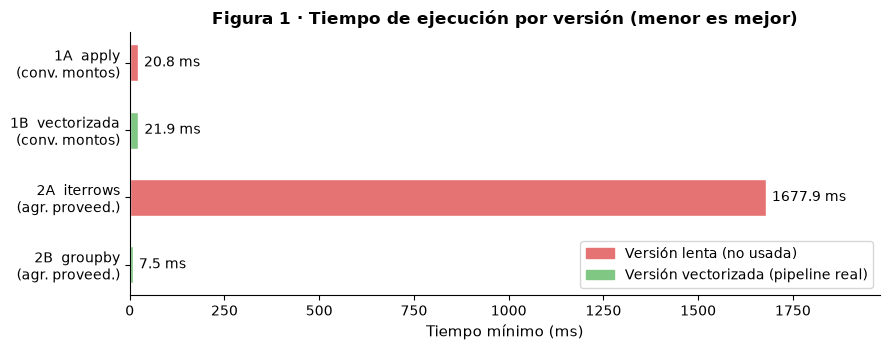

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(9, 3.6))

versiones = [
    "1A  apply\n(conv. montos)",
    "1B  vectorizada\n(conv. montos)",
    "2A  iterrows\n(agr. proveed.)",
    "2B  groupby\n(agr. proveed.)",
]
tiempos = [tiempo_a * 1000, tiempo_b * 1000, tiempo_c * 1000, tiempo_d * 1000]
colores = ["#e57373", "#81c784", "#e57373", "#81c784"]

bars = ax.barh(versiones, tiempos, color=colores, edgecolor="white", height=0.55)
ax.set_xlabel("Tiempo mínimo (ms)", fontsize=11)
ax.set_title("Figura 1 · Tiempo de ejecución por versión (menor es mejor)", fontsize=12, fontweight="bold")
ax.invert_yaxis()

for bar, t in zip(bars, tiempos):
    ax.text(bar.get_width() + max(tiempos) * 0.01, bar.get_y() + bar.get_height() / 2,
            f"{t:.1f} ms", va="center", fontsize=10)

patch_a = mpatches.Patch(color="#e57373", label="Versión lenta (no usada)")
patch_b = mpatches.Patch(color="#81c784", label="Versión vectorizada (pipeline real)")
ax.legend(handles=[patch_a, patch_b], loc="lower right", fontsize=10)
ax.set_xlim(0, max(tiempos) * 1.18)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


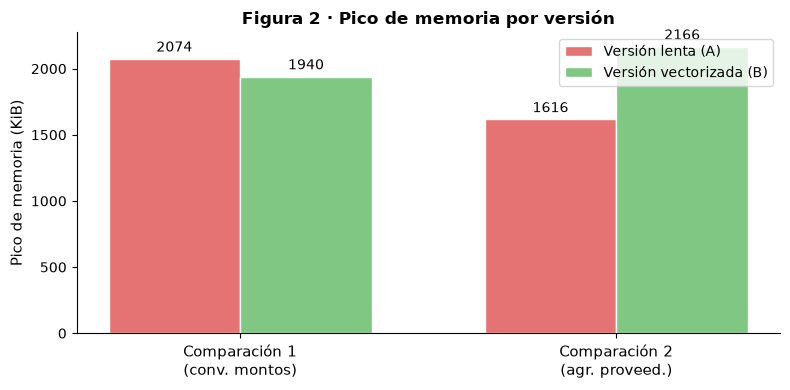

In [15]:
import numpy as np

fig, ax = plt.subplots(figsize=(8, 4))

etiquetas = ["Comparación 1\n(conv. montos)", "Comparación 2\n(agr. proveed.)"]
mem_lenta  = [mem_a,  mem_c]   # versiones A
mem_rapida = [mem_b,  mem_d]   # versiones B

x = np.arange(len(etiquetas))
ancho = 0.35

b1 = ax.bar(x - ancho/2, mem_lenta,  ancho, label="Versión lenta (A)",  color="#e57373", edgecolor="white")
b2 = ax.bar(x + ancho/2, mem_rapida, ancho, label="Versión vectorizada (B)", color="#81c784", edgecolor="white")

ax.set_ylabel("Pico de memoria (KiB)", fontsize=11)
ax.set_title("Figura 2 · Pico de memoria por versión", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(etiquetas, fontsize=11)
ax.legend(fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

for rect in list(b1) + list(b2):
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2, h + 30, f"{h:.0f}",
            ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()


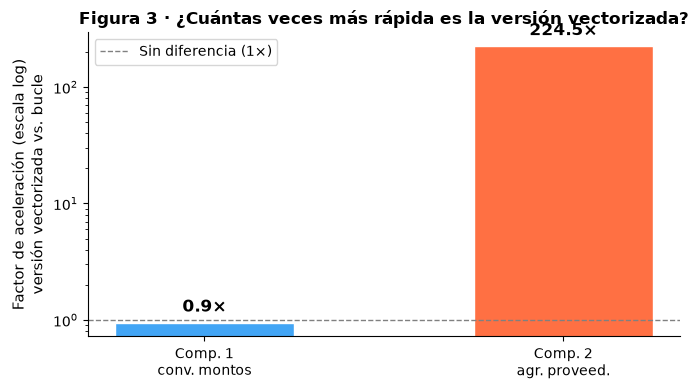

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))

operaciones = ["Comp. 1\nconv. montos", "Comp. 2\nagr. proveed."]
aceleraciones = [tiempo_a / tiempo_b, tiempo_c / tiempo_d]
colores_acc = ["#42a5f5", "#ff7043"]

bars_acc = ax.bar(operaciones, aceleraciones, color=colores_acc, edgecolor="white", width=0.5)
ax.set_yscale("log")
ax.set_ylabel("Factor de aceleración (escala log)\nversión vectorizada vs. bucle", fontsize=11)
ax.set_title("Figura 3 · ¿Cuántas veces más rápida es la versión vectorizada?", fontsize=12, fontweight="bold")
ax.axhline(1, color="gray", linewidth=1, linestyle="--", label="Sin diferencia (1×)")
ax.legend(fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

for bar, acc in zip(bars_acc, aceleraciones):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.15,
            f"{acc:.1f}×", ha="center", va="bottom", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()


## Conclusión

Las dos comparaciones confirman que las implementaciones vectorizadas que usa el
pipeline son la elección correcta:

- En la **conversión de montos**, `str.replace` + `pd.to_numeric` es más rápido que
  `apply`, con un costo de memoria equivalente.
- En la **agregación por proveedor**, `groupby` es más rápido que `iterrows`, con
  un pico de memoria mayor pero completamente manejable con el volumen real del
  proyecto (≈ 25 000 órdenes).

El principio general es el mismo en ambos casos: las operaciones vectorizadas de
pandas y NumPy trabajan sobre arrays contiguos en memoria con código compilado en C,
mientras que los bucles en Python construyen y destruyen un objeto por cada fila.
La diferencia se hace más pronunciada a medida que crece el dataset.